   buyurtma_id        sana     toifa  tolov  summa
0            1  2025-07-01      Shim   naqd    210
1            2  2025-07-04    Kurtka  karta    540
2            3  2025-07-05  Poyabzal   naqd    480
3            4  2025-07-06      Shim  karta    180
4            5  2025-07-06      Shim  karta    250


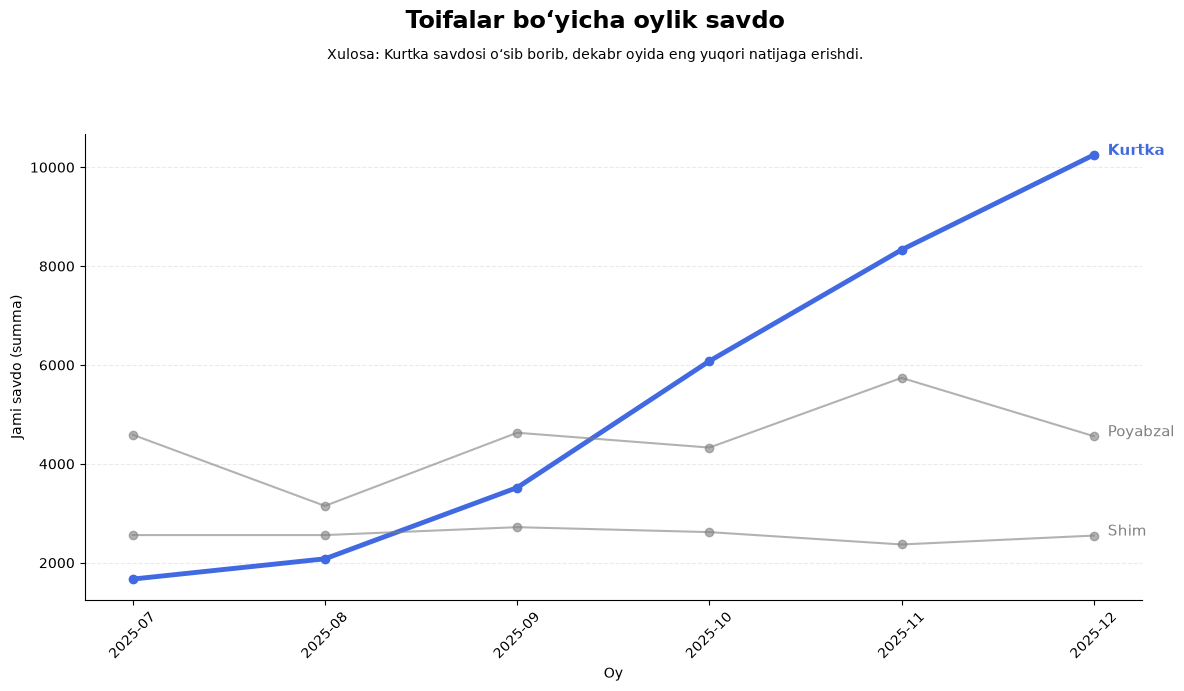

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
dataframe = 'data/Oq3OsQ0HJQPqkO75oqFvgyqLAZadw5ymjsAmYagZ.csv'

df = pd.read_csv(dataframe)
df["sana"] = pd.to_datetime(df["sana"])
df["oy"] = df["sana"].dt.to_period("M")

oylik_savdo = df.groupby(["oy", "toifa"])["summa"].sum().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(12, 7))
for toifa in oylik_savdo.columns:
    y = oylik_savdo[toifa].values
    x = range(len(y))

    if toifa == "Kurtka":
        ax.plot(x, y, color="royalblue", marker="o", linewidth=3.5)
    else:
        ax.plot(x, y, color="gray", marker="o", linewidth=1.5, alpha=0.6)

    ax.annotate(
        toifa,
        (len(y) - 1, y[-1]),
        xytext=(10, 0),
        textcoords="offset points",
        color="royalblue" if toifa == "Kurtka" else "gray",
        fontsize=11,
        fontweight="bold" if toifa == "Kurtka" else "normal"
    )

if "Kurtka" in oylik_savdo.columns:
    y = oylik_savdo["Kurtka"].values
    x = len(y) - 1
ax.set_xticks(range(len(oylik_savdo.index)))
ax.set_xticklabels(oylik_savdo.index.astype(str), rotation=45)
fig.suptitle("Toifalar bo‘yicha oylik savdo", fontsize=17, fontweight="bold")
fig.text(
    0.5, 0.91,
    "Xulosa: Kurtka savdosi o‘sib borib, dekabr oyida eng yuqori natijaga erishdi.",
    ha="center",
    fontsize=10
)
ax.set_xlabel("Oy")
ax.set_ylabel("Jami savdo (summa)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.25)
plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.savefig("shop/grafik.png", dpi=300, bbox_inches="tight")
plt.show()






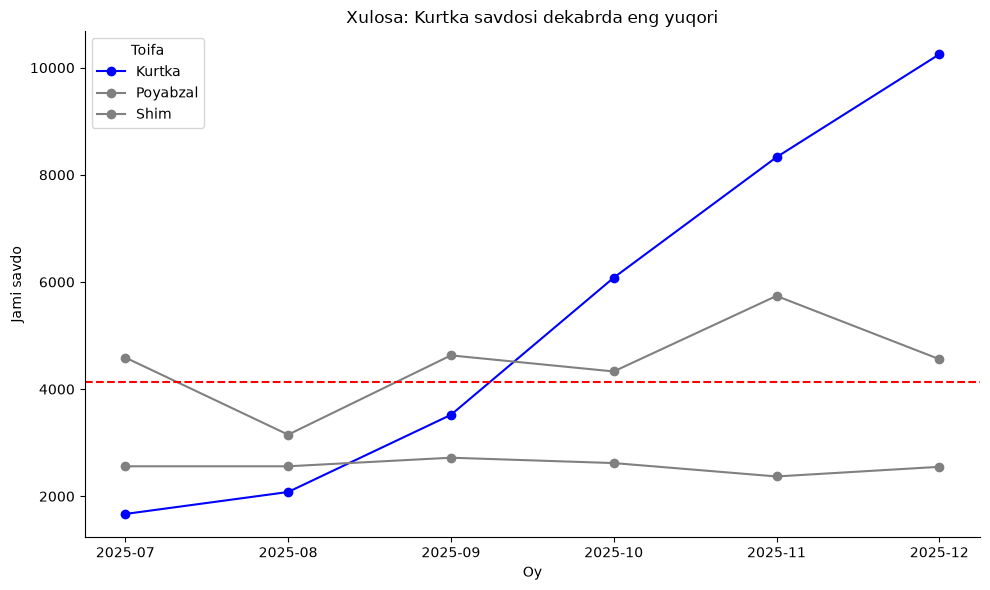

In [ ]:
oylik_savdo = df.groupby(["oy", "toifa"])["summa"].sum().unstack()
fig, ax = plt.subplots(figsize=(10, 6))
for toifa in oylik_savdo.columns:
    rang = "blue" if toifa == "Kurtka" else "gray"
    ax.plot(oylik_savdo.index.astype(str), oylik_savdo[toifa],
            marker="o", color=rang, label=toifa)
ortacha = oylik_savdo.mean().mean()
ax.axline((0, ortacha), slope=0, color="red", linestyle="--")
kurtka = oylik_savdo["Kurtka"]
eng_past_oy = kurtka.idxmin()
eng_past_summa = kurtka.min()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.title("Xulosa: Kurtka savdosi dekabrda eng yuqori")
plt.xlabel("Oy")
plt.ylabel("Jami savdo")
plt.legend(title="Toifa")
plt.tight_layout()
plt.show()

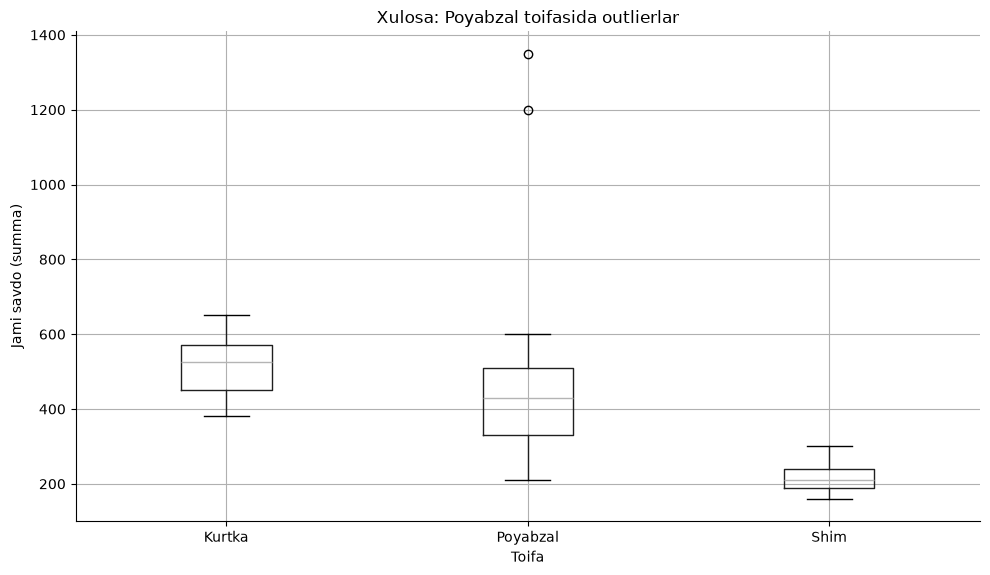

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

df.boxplot(column="summa", by="toifa", ax=ax)
poyabzal = df[df["toifa"] == "Poyabzal"]["summa"]
Q1 = poyabzal.quantile(0.25)
Q3 = poyabzal.quantile(0.75)
IQR = Q3 - Q1
outlierlar = poyabzal[
    (poyabzal < Q1 - 1.5 * IQR) |
    (poyabzal > Q3 + 1.5 * IQR)
]
plt.title("Xulosa: Poyabzal toifasida outlierlar")
plt.suptitle("")
plt.xlabel("Toifa")
plt.ylabel("Jami savdo (summa)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()